# 04 · Curved spaces in Python

Companion notebook for *Questioning the mathematical foundations of AI*, Dr Ana Rojo-Echeburúa, PyCon España 2026.

## What this notebook does

At the end of notebook 02 I listed the costs of curved spaces: precision near the edge, trickier training, and no support in vector databases. Here's the good news. The maths is already packaged, and one `pip install` gets you started.

This notebook is a hands-on tour of four Python packages. Each one gets a short definition, a one-line install and a small example that runs on a laptop CPU.

| Package | What it is | Built on | Reference |
|---|---|---|---|
| **geoopt** | Curved spaces as drop-in PyTorch pieces: Poincaré ball, Lorentz model, sphere, product manifolds, plus optimisers that follow the curve (RiemannianAdam, RiemannianSGD). | PyTorch | Kochurov, Karimov & Kozlukov, *Geoopt: Riemannian Optimization in PyTorch*, arXiv 2020 |
| **gensim · PoincareModel** | The quickest start. Give it (child, parent) pairs and it trains Poincaré embeddings for you. | NumPy | Nickel & Kiela, NeurIPS 2017 (the method). Řehůřek & Sojka, LREC Workshop 2010 (gensim) |
| **HypLL** (Hyperbolic Learning Library) | Hyperbolic versions of neural network layers (linear, convolution and more), so you can build whole hyperbolic models. | PyTorch | van Spengler, Wirth & Mettes, ACM Multimedia 2023 (arXiv 2306.06154) |
| **geomstats** | Geometry and statistics on manifolds: distances, means and geodesics on spheres, hyperbolic spaces and more. | NumPy / PyTorch backends | Miolane et al., JMLR 21, 2020 |

```bash
pip install geoopt gensim hypll geomstats torch numpy matplotlib
```

## Four ideas to keep in your head

- **Manifold.** A space that looks flat if you zoom in far enough but can be curved overall, like the surface of the Earth.
- **Curvature.** Zero is flat. Positive closes in on itself (a sphere). Negative opens up faster and faster (hyperbolic space).
- **Exponential map (`expmap0`).** The standard way to take a point from ordinary flat space and place it on the curved space, starting from the centre. `logmap0` goes back.
- **Riemannian optimiser.** Gradient descent that takes its steps along the curved space, so points never leave it (for the Poincaré ball, they never cross the edge).

## The steps

1. **geoopt: distances in the Poincaré ball.** The edge effect in two numbers, and the precision problem.
2. **geoopt: the Lorentz model.** Same geometry, different picture.
3. **geoopt: training on a curved space.** Why you need an optimiser that follows the curve.
4. **geoopt: product manifolds.** Mixing hyperbolic, spherical and flat pieces.
5. **gensim: the quickest start.** From a list of pairs to a hyperbolic embedding in five lines.
6. **HypLL: hyperbolic neural network layers.** A forward pass through a hyperbolic linear layer.
7. **geomstats: three curvatures side by side.** Geodesics and circles on a sphere, a plane and a hyperbolic disk.
8. **What about vector databases?** Brute force and re-ranking.
9. **Takeaway.**

## Setup

One thing to flag before we start. geomstats 2.8.0 still imports `numpy.trapz`, which recent NumPy versions removed (it's called `numpy.trapezoid` now). The one-line fix below puts the old name back before geomstats is imported. If you're on an older NumPy, or a newer geomstats, it does nothing.

In [1]:
import os
import time
import logging
import warnings
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
logging.getLogger("gensim").setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

import numpy as np
if not hasattr(np, "trapz"):          # geomstats 2.8.0 still uses the old NumPy name
    np.trapz = np.trapezoid
os.environ.setdefault("GEOMSTATS_BACKEND", "numpy")

import matplotlib.pyplot as plt
import torch
import geoopt
import gensim
import hypll
import geomstats
from importlib.metadata import version

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

BG, TEXT = "#CFD5D3", "#030303"
BROWN, DARK_BROWN, SLATE, LIGHT_GREY = "#7F584A", "#4F3733", "#767F87", "#A9B0B4"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT, "axes.edgecolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "figure.dpi": 110,
})

def draw_disk(ax, title=None, lim=1.08):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=TEXT, lw=1.2))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize=11)

for pkg in ["geoopt", "gensim", "hypll", "geomstats", "torch", "numpy"]:
    print(f"{pkg:<10}{version(pkg)}")

geoopt    0.5.1
gensim    4.4.0
hypll     0.1.1
geomstats 2.8.0
torch     2.15.0
numpy     2.5.4


**What you're seeing:** the exact versions behind every output in this notebook. Curved-space libraries are young and their APIs move, so if something breaks for you, compare versions first.

## Step 1 · geoopt: distances in the Poincaré ball

`geoopt.PoincareBall(c=1.0)` is the Poincaré ball from notebook 02. The parameter `c` sets the curvature, which is $-c$, so `c=1.0` is the standard hyperbolic space with curvature $-1$.

**The edge effect in two numbers.** Take four points on a line through the centre. From the centre to 0.09 is a step of 0.09 on your ruler, and so is the step from 0.90 to 0.99. In hyperbolic distance they're nothing alike. (I use double precision here. In PyTorch's default float32 the second distance prints as 2.3488 instead of 2.3489, which is a small preview of the precision problem below.)

In [2]:
ball = geoopt.PoincareBall(c=1.0)

f64 = dict(dtype=torch.float64)          # double precision, so the last digit matches the slide
o = torch.tensor([0.00, 0.0], **f64)   # centre
p = torch.tensor([0.09, 0.0], **f64)
q = torch.tensor([0.90, 0.0], **f64)   # near the edge
r = torch.tensor([0.99, 0.0], **f64)

d_op, d_qr, d_oq = ball.dist(o, p).item(), ball.dist(q, r).item(), ball.dist(o, q).item()
print(f"d(centre, 0.09) = {d_op:.4f}")
print(f"d(0.90, 0.99)   = {d_qr:.4f}")
print(f"d(centre, 0.90) = {d_oq:.4f}")
print(f"\nsame ruler step of 0.09, {d_qr / d_op:.1f} times further near the edge")

def poincare_dist(u, v):
    u, v = np.asarray(u, float), np.asarray(v, float)
    return np.arccosh(1 + 2 * np.sum((u - v) ** 2) / ((1 - np.sum(u ** 2)) * (1 - np.sum(v ** 2))))

for (u, v), d in [((o, p), d_op), ((q, r), d_qr), ((o, q), d_oq)]:
    assert np.isclose(poincare_dist(u.numpy(), v.numpy()), d, atol=1e-5)
print("geoopt matches the Poincaré formula by hand: OK")

d(centre, 0.09) = 0.1805
d(0.90, 0.99)   = 2.3489
d(centre, 0.90) = 2.9444

same ruler step of 0.09, 13.0 times further near the edge
geoopt matches the Poincaré formula by hand: OK


**What you're seeing:** these are the numbers from the slide. From the centre to 0.09 is 0.1805, and from 0.90 to 0.99 is 2.3489, so the same ruler step is about 13 times further near the edge. The centre to 0.90 is already 2.9444. geoopt and the formula by hand agree, so there's nothing hidden in the library.

**Plot it.** The distance from the centre to a point $x$ is $d(0, x) = 2\operatorname{artanh}(\lVert x \rVert)$. Next to the flat distance $\lVert x \rVert$ you can see where all the room is.

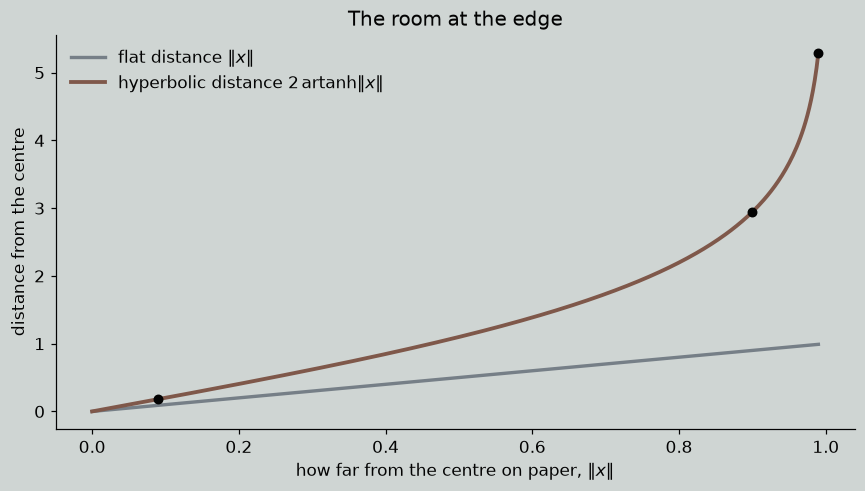

In [3]:
s = np.linspace(0, 0.99, 400)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(s, s, color=SLATE, lw=2.2, label=r"flat distance $\|x\|$")
ax.plot(s, 2 * np.arctanh(s), color=BROWN, lw=2.5, label=r"hyperbolic distance $2\,\mathrm{artanh}\|x\|$")
for x0 in [0.09, 0.9, 0.99]:
    ax.scatter(x0, 2 * np.arctanh(x0), color=TEXT, zorder=3, s=30)
ax.set_xlabel(r"how far from the centre on paper, $\|x\|$")
ax.set_ylabel("distance from the centre")
ax.set_title("The room at the edge")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What you're seeing:** the two curves sit almost on top of each other near the centre (at 0.09 the hyperbolic distance is only about twice the flat one) and then the hyperbolic one takes off. That steep climb on the right is the room at the edge, the whole reason trees fit in hyperbolic space.

**The precision problem.** All that room sits in a thin band near $\lVert x \rVert = 1$, and floating-point numbers have only so many digits to describe it. Take $x = 1 - 10^{-k}$ for $k = 1, \dots, 9$ and compute $d(0, x)$ in `float32` and `float64`, both straight from the formula and through geoopt.

In [4]:
print(f"{'k':>2} {'x in float32':>14} {'formula f32':>12} {'geoopt f32':>11} {'formula f64':>12}")
for k in range(1, 10):
    x32 = np.float32(1) - np.float32(10.0 ** -k)
    x64 = 1 - 10.0 ** -k
    with np.errstate(divide="ignore"):
        f32 = 2 * np.arctanh(x32)
    g32 = ball.dist0(torch.tensor([float(x32), 0.0], dtype=torch.float32)).item()
    print(f"{k:>2} {x32:>14.9f} {f32:>12.4f} {g32:>11.4f} {2 * np.arctanh(x64):>12.4f}")

 k   x in float32  formula f32  geoopt f32  formula f64
 1    0.899999976       2.9444      2.9444       2.9444
 2    0.990000010       5.2933      5.2933       5.2933
 3    0.999000013       7.6004      7.6004       7.6004
 4    0.999899983       9.9033      9.9027       9.9034
 5    0.999989986      12.2047     12.1988      12.2061
 6    0.999998987      14.4955     14.4383      14.5087
 7    0.999999881      16.6355     16.2301      16.8112
 8    1.000000000          inf     16.6355      19.1138
 9    1.000000000          inf     16.6355      21.4164


**What you're seeing:** in float32, $1 - 10^{-k}$ starts drifting from the true value at $k = 4$, and by $k = 8$ it rounds to exactly 1.0, so the formula returns `inf`. The double-precision column keeps going (19.1 and 21.4). Look at the geoopt column, though. It never returns `inf`, because geoopt quietly clamps points a little inside the edge to stay safe, and at $k = 8$ and $k = 9$ it reports 16.64 for points that should be at 19.11 and 21.42. That's sensible engineering, but it means precision errors near the edge are **silent**. This is why Sala et al. (ICML 2018) needed about 500 bits per number for their exact 2-dimensional tree, and why in practice people use more dimensions at 32 bits (about 10).

**`expmap0` and `logmap0`.** The usual way to get a point into the ball is to start with an ordinary vector (for example, the output of a normal neural network) and walk along the curved space from the centre in that direction, for that length. That's `expmap0`. `logmap0` reverses it.

largest norm before: 3.777
largest norm after:  0.99895 (always inside the unit disk)
logmap0 recovers the vectors: True


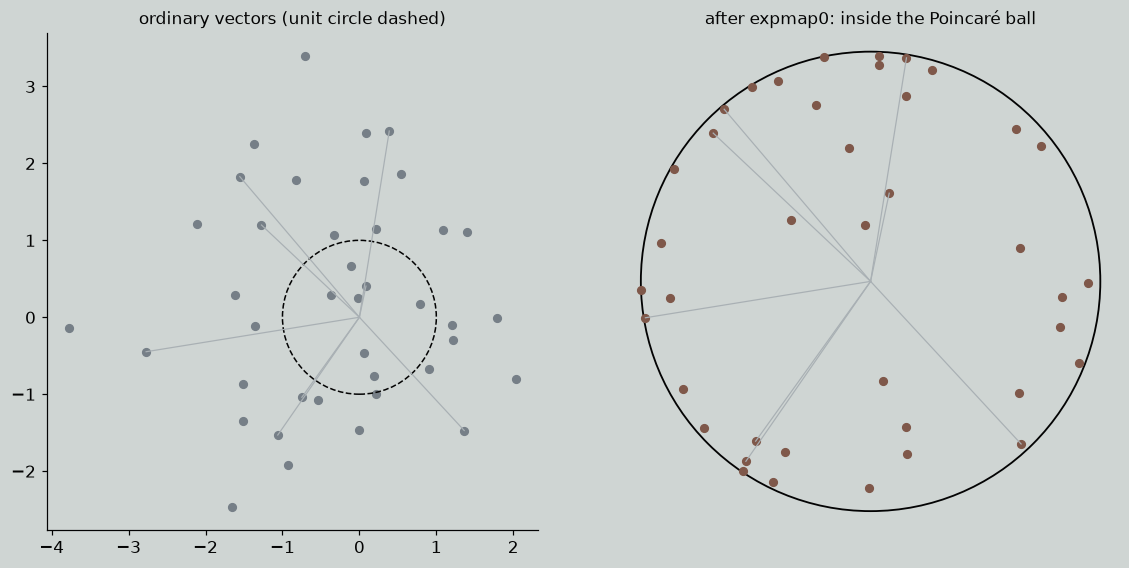

In [5]:
torch.manual_seed(SEED)
V = torch.randn(40, 2, dtype=torch.float64) * 1.2       # ordinary 2-d vectors
P = ball.expmap0(V)                                     # placed on the ball
V_back = ball.logmap0(P)

print("largest norm before:", round(V.norm(dim=1).max().item(), 3))
print("largest norm after: ", round(P.norm(dim=1).max().item(), 5), "(always inside the unit disk)")
print("logmap0 recovers the vectors:", torch.allclose(V_back, V, atol=1e-6))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
axes[0].scatter(V[:, 0], V[:, 1], color=SLATE, s=25)
axes[0].add_patch(plt.Circle((0, 0), 1, fill=False, color=TEXT, lw=1, ls="--"))
axes[0].set_aspect("equal"); axes[0].set_title("ordinary vectors (unit circle dashed)", fontsize=11)
draw_disk(axes[1], "after expmap0: inside the Poincaré ball")
axes[1].scatter(P[:, 0], P[:, 1], color=BROWN, s=25)
for v, p_ in zip(V[:8], P[:8]):
    axes[0].plot([0, v[0]], [0, v[1]], color=LIGHT_GREY, lw=0.8)
    axes[1].plot([0, p_[0]], [0, p_[1]], color=LIGHT_GREY, lw=0.8)
plt.tight_layout(); plt.show()

**What you're seeing:** on the left, ordinary vectors with lengths up to 3.8, many of them well outside the unit circle. On the right, the same vectors after `expmap0`. Every direction is kept, every point lands inside the disk, and the long vectors end up crowded near the edge, because a long walk in hyperbolic space covers a lot of distance in very little paper. `logmap0` gives back the original vectors exactly.

## Step 2 · geoopt: same geometry, different model (Lorentz)

The Poincaré ball is one picture of hyperbolic space. The **Lorentz model** (or hyperboloid) is another. It's the bowl-shaped surface $-x_0^2 + x_1^2 + \dots + x_n^2 = -1$ with $x_0 > 0$, sitting in one extra dimension. People like it for training because it has no edge, so nothing is squashed against a boundary and gradients behave better (Nickel & Kiela, ICML 2018).

The two pictures describe the same space, and there's an exact map between them. For curvature $-1$:

$$x \;\longmapsto\; \frac{(1 + \lVert x \rVert^2,\; 2x)}{1 - \lVert x \rVert^2}.$$

Before comparing distances I checked geoopt's conventions in the installed version. `geoopt.Lorentz()` has a parameter `k` with curvature $-1/k$ (so the default `k=1` is curvature $-1$, the same as our ball), the time-like coordinate $x_0$ comes **first**, and the docs recommend double precision. That all lines up with the map above.

In [6]:
lorentz = geoopt.Lorentz().double()     # k = 1, curvature -1, double precision as geoopt recommends

def poincare_to_lorentz(x):
    n = (x ** 2).sum(-1, keepdim=True)
    return torch.cat([(1 + n) / (1 - n), 2 * x / (1 - n)], dim=-1)

print(f"{'pair':<16}{'Poincaré ball':>15}{'Lorentz':>15}")
for name, (u, v) in {"centre, 0.09": (o, p), "0.90, 0.99": (q, r)}.items():
    U, Vv = poincare_to_lorentz(u.double()), poincare_to_lorentz(v.double())
    assert lorentz.check_point_on_manifold(U) and lorentz.check_point_on_manifold(Vv)
    print(f"{name:<16}{ball.dist(u.double(), v.double()).item():15.6f}{lorentz.dist(U, Vv).item():15.6f}")
print("\nboth images satisfy -x0^2 + x1^2 + x2^2 = -1: OK")

pair              Poincaré ball        Lorentz
centre, 0.09           0.180488       0.180488
0.90, 0.99             2.348863       2.348866

both images satisfy -x0^2 + x1^2 + x2^2 = -1: OK


**What you're seeing:** the same two pairs of points, measured in the Poincaré ball and on the hyperboloid, give the same distances (0.180488, and 2.34886 to five decimals). Both images pass geoopt's check that they lie on the hyperboloid. Two pictures, one geometry, and you can move between them with one line of code.

## Step 3 · geoopt: training on a curved space

Now the part that matters for machine learning. We train the tiny hierarchy from notebook 02 directly in geoopt. Every word is a point stored as a `geoopt.ManifoldParameter` on the ball, and the loss is the one from Nickel & Kiela (NeurIPS 2017): pull linked words together and push everything else away.

Then we run **exactly the same code twice**, changing one line. Once with `geoopt.optim.RiemannianAdam`, which steps along the curved space, and once with plain `torch.optim.Adam`, which doesn't know the space is curved.

In [7]:
rels = [("dog", "mammal"), ("cat", "mammal"), ("whale", "mammal"),
        ("mammal", "animal"), ("eagle", "bird"), ("owl", "bird"), ("bird", "animal"),
        ("invoice", "document"), ("receipt", "document"), ("contract", "document")]
words = sorted({w for pair in rels for w in pair})
index = {w: i for i, w in enumerate(words)}
n = len(words)

E = torch.tensor([[index[a], index[b]] for a, b in rels])
linked = torch.zeros(n, n, dtype=torch.bool)
for a, b in E.tolist():
    linked[a, b] = linked[b, a] = True
U_idx, V_idx = torch.cat([E[:, 0], E[:, 1]]), torch.cat([E[:, 1], E[:, 0]])
rows = torch.arange(len(U_idx))
skip = linked[U_idx].clone(); skip[rows, V_idx] = False; skip[rows, U_idx] = True

def train(make_optimiser, steps=500):
    torch.manual_seed(SEED)
    X = geoopt.ManifoldParameter(torch.empty(n, 2, dtype=torch.float64).uniform_(-1e-3, 1e-3), manifold=ball)
    opt = make_optimiser([X])
    first_outside, max_norms = None, []
    for step in range(steps):
        opt.zero_grad()
        D = ball.dist(X[:, None, :], X[None, :, :])
        loss = (torch.logsumexp((-D[U_idx]).masked_fill(skip, -1e9), dim=1) + D[U_idx, V_idx]).mean()
        loss.backward()
        opt.step()
        m = X.detach().norm(dim=1).max().item()
        max_norms.append(m)
        if m >= 1 and first_outside is None:
            first_outside = step
    return X.detach(), loss.item(), first_outside, max_norms

X_riem, loss_riem, out_riem, norms_riem = train(lambda ps: geoopt.optim.RiemannianAdam(ps, lr=0.05))
X_adam, loss_adam, out_adam, norms_adam = train(lambda ps: torch.optim.Adam(ps, lr=0.05))       # the one-line difference

print(f"RiemannianAdam: final loss {loss_riem:.3f}, largest norm {X_riem.norm(dim=1).max():.4f}, first step outside the ball: {out_riem}")
print(f"plain Adam:     final loss {loss_adam:.3f}, largest norm {X_adam.norm(dim=1).max():.4f}, first step outside the ball: {out_adam}")

RiemannianAdam: final loss 0.116, largest norm 0.9994, first step outside the ball: None
plain Adam:     final loss 1.408, largest norm 2.0037, first step outside the ball: 20


**What you're seeing:** with RiemannianAdam the loss drops to 0.116 and the largest norm stays at 0.9994, inside the ball. With plain Adam the very same code puts a point outside the ball by step 20, and by the end one sits at norm 2.0. Out there the Poincaré distance formula no longer means anything, which is why the loss ends at 1.408 and the training is effectively broken. One line changed, and that line is the optimiser.

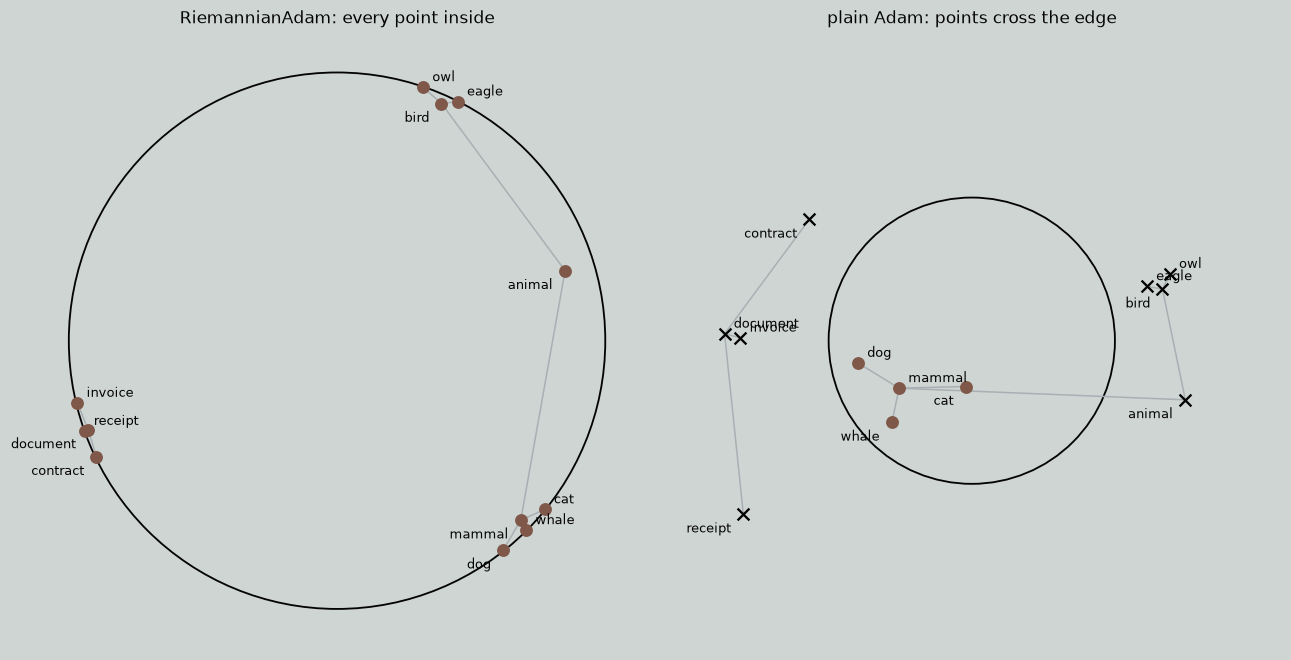

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, X, title in [(axes[0], X_riem, "RiemannianAdam: every point inside"),
                     (axes[1], X_adam, "plain Adam: points cross the edge")]:
    lim = max(1.08, X.norm(dim=1).max().item() + 0.15)
    draw_disk(ax, title, lim=lim)
    for a, b in rels:
        ax.plot(*zip(X[index[a]].numpy(), X[index[b]].numpy()), color=LIGHT_GREY, lw=1, zorder=1)
    outside = X.norm(dim=1) >= 1
    ax.scatter(X[~outside, 0], X[~outside, 1], color=BROWN, s=55, zorder=3)
    ax.scatter(X[outside, 0], X[outside, 1], color=TEXT, marker="x", s=60, zorder=3)
    order = sorted(index, key=lambda w: (round(float(X[index[w], 0]), 1), float(X[index[w], 1])))
    for k, w in enumerate(order):         # alternate label positions so close neighbours don't overlap
        ax.annotate(w, X[index[w]].numpy(), xytext=(6, 4) if k % 2 == 0 else (-8, -12), ha="left" if k % 2 == 0 else "right",
                    textcoords="offset points", fontsize=8.5)
plt.tight_layout(); plt.show()

**What you're seeing:** on the left, the hierarchy learned with RiemannianAdam, every point inside the disk and each branch heading off in its own direction. It's rougher than gensim's version in Step 5 (even animal drifts out towards the edge), because this bare-bones loop has none of gensim's extras like a burn-in phase with a small learning rate, but the geometry is behaving. On the right, plain Adam, where the crosses mark points that have left the ball altogether. This is the main practical reason you need optimisers that follow the curve.

## Step 4 · geoopt: product manifolds (mix the shapes)

Real data is rarely just one shape. An org chart is a tree (hyperbolic), the days of the week loop round (a circle, so spherical), and plain "these two things are similar" is fine in flat space. A **product manifold** glues several spaces together, and a point is simply one point in each piece, stacked into one vector.

In the installed geoopt, `geoopt.ProductManifold` takes `(manifold, shape)` pairs. For a product, the squared distance is the sum of the squared distances in each piece:

$$d\big((x_1, x_2, x_3), (y_1, y_2, y_3)\big)^2 = d_{\text{hyp}}(x_1, y_1)^2 + d_{\text{sph}}(x_2, y_2)^2 + d_{\text{flat}}(x_3, y_3)^2 .$$

In [9]:
sphere, flat = geoopt.Sphere(), geoopt.Euclidean(ndim=1)
product = geoopt.ProductManifold((ball, 2), (sphere, 3), (flat, 2))
print(product)

x = torch.cat([torch.tensor([0.3, 0.1], **f64), torch.tensor([1.0, 0.0, 0.0], **f64), torch.tensor([1.0, 2.0], **f64)])
y = torch.cat([torch.tensor([-0.2, 0.5], **f64), torch.tensor([0.0, 1.0, 0.0], **f64), torch.tensor([0.0, -1.0], **f64)])
print("a point is just the pieces glued together:", x.numpy())

parts = [ball.dist(x[:2], y[:2]).item(), sphere.dist(x[2:5], y[2:5]).item(), flat.dist(x[5:], y[5:]).item()]
print(f"\nhyperbolic piece {parts[0]:.4f}, spherical piece {parts[1]:.4f}, flat piece {parts[2]:.4f}")
print(f"product distance {product.dist(x, y).item():.10f}")
print(f"sqrt(sum of squares) {np.sqrt(sum(d ** 2 for d in parts)):.10f}")

(PoincareBall)x(Sphere)x(Euclidean) manifold
a point is just the pieces glued together: [0.3 0.1 1.  0.  0.  1.  2. ]

hyperbolic piece 1.4669, spherical piece 1.5708, flat piece 3.1623
product distance 3.8235149408
sqrt(sum of squares) 3.8235149408


**What you're seeing:** the 7-number vector is a point in the Poincaré disk (2 numbers), a point on the sphere (3 numbers) and a point in the plane (2 numbers), glued together. The product distance, 3.8235149408, matches the square root of the sum of the three squared distances to every printed digit.

Gu, Sala, Gunel & Ré (ICLR 2019) take this one step further and **learn** the curvature of each piece from the data, so training sets how much of your data is tree-like, how much is cyclic and how much is flat. On graphs with mixed structure, these mixed-curvature embeddings beat any single space.

## Step 5 · gensim: the quickest start

If you just want to see a hierarchy in hyperbolic space, gensim's `PoincareModel` is the shortest path. It implements Nickel & Kiela (NeurIPS 2017) and needs nothing but (child, parent) pairs. This is the model the talk's live demo uses, and you've already seen its picture in notebook 02 (Step 4), so here we focus on what the API gives you.

In [10]:
from gensim.models.poincare import PoincareModel

model = PoincareModel(rels, size=2, negative=2, seed=0)
model.train(epochs=300)
kv = model.kv

print("distance(dog, mammal):", round(kv.distance("dog", "mammal"), 4))
print("norm(animal):", round(float(kv.norm("animal")), 4), "  norm(dog):", round(float(kv.norm("dog")), 4))
print("closest_parent('dog'):", kv.closest_parent("dog"))
print("ancestors('dog'):     ", kv.ancestors("dog"))
print("descendants('animal'):", kv.descendants("animal"))

distance(dog, mammal): 1.3751
norm(animal): 0.1217   norm(dog): 0.7602
closest_parent('dog'): whale
ancestors('dog'):      ['whale', 'cat', 'mammal', 'animal']
descendants('animal'): ['mammal', 'cat', 'whale', 'dog', 'eagle']


**What you're seeing:** gensim gives you distances and norms directly. animal has norm 0.12 and dog 0.76, so general near the centre and specific near the edge. Now look at `closest_parent("dog")`, which returns **whale**. gensim's helper defines a node's parent as the closest node with a smaller norm, which is a heuristic that can pick the wrong node. In this tiny 2-d model whale happens to have a slightly smaller norm than dog and sits close to it, so the heuristic picks it, and the ancestor chain inherits that mistake. Use these helpers for exploring, and check them against the relations you trained on. That's five lines from a list of pairs to a hyperbolic embedding you can query.

## Step 6 · HypLL: hyperbolic neural network layers

geoopt gives you curved spaces and optimisers. HypLL (van Spengler, Wirth & Mettes, ACM Multimedia 2023) gives you **layers**, hyperbolic versions of the PyTorch building blocks (`HLinear`, `HConvolution2d`, `HReLU`, `HBatchNorm` and more), so you can build an entire network that lives in hyperbolic space.

I followed the quickstart pattern from the installed package (version 0.1.1): make a manifold, wrap ordinary data as a `TangentTensor`, map it onto the ball with `expmap`, and pass it through hyperbolic layers. Everything that comes out is a `ManifoldTensor`, a tensor that carries the manifold it lives on.

**One gotcha I found while checking the API:** `Curvature(value=1.0)` doesn't give curvature 1. By default HypLL passes the value through `softplus` to keep it positive while it's being learned, so `value=1.0` becomes $c = \log(1 + e) \approx 1.313$. To fix $c = 1$ exactly, pass an identity constraint.

In [11]:
from hypll.manifolds.poincare_ball import Curvature, PoincareBall
from hypll.tensors import TangentTensor
from hypll import nn as hnn

print("Curvature(value=1.0) gives c =", round(Curvature(value=1.0)().item(), 4))

manifold = PoincareBall(c=Curvature(value=1.0, constraining_strategy=lambda t: t))
print("with an identity constraint:  c =", manifold.c().item())

torch.manual_seed(SEED)
data = torch.randn(4, 3) * 0.5                                  # a batch of 4 ordinary 3-d vectors
x_hyp = manifold.expmap(TangentTensor(data=data, man_dim=1, manifold=manifold))

net = torch.nn.Sequential(
    hnn.HLinear(in_features=3, out_features=2, manifold=manifold),
    hnn.HReLU(manifold=manifold),
)
out = net(x_hyp)

print("\ninput type: ", type(x_hyp).__name__, "| norms", np.round(x_hyp.tensor.norm(dim=1).numpy(), 4))
print("output type:", type(out).__name__, "| norms", np.round(out.tensor.detach().norm(dim=1).numpy(), 4))
print("trainable parameters:", sum((p.tensor if hasattr(p, "tensor") else p).numel() for p in net.parameters()))

Curvature(value=1.0) gives c = 1.3133
with an identity constraint:  c = 1.0

input type:  ManifoldTensor | norms [0.8722 0.7303 0.5284 0.3552]
output type: ManifoldTensor | norms [0.4624 0.5001 0.0936 0.2535]
trainable parameters: 9


**What you're seeing:** the default `Curvature(value=1.0)` really does give $c = 1.3133$, and the identity constraint fixes it at 1.0. Four ordinary 3-d vectors go in, get mapped onto the ball, pass through a hyperbolic linear layer and a hyperbolic ReLU, and come out as four points on the 2-d ball (still a `ManifoldTensor`, with all norms below 1). The layer has 9 trainable parameters, the same count as an ordinary `nn.Linear(3, 2)`. From here you can stack layers and train with a Riemannian optimiser, just as you would in plain PyTorch.

## Step 7 · geomstats: three curvatures side by side

geomstats (Miolane et al., JMLR 2020) is the most general of the four. It covers dozens of manifolds with a common interface, and supports NumPy, PyTorch and other backends (you pick one with the `GEOMSTATS_BACKEND` environment variable, which we set to `numpy` in the setup). In version 2.8.0 the spaces we want are `Hypersphere`, `Euclidean` and `PoincareBall`, each with a `metric` that gives `dist` and `geodesic`.

First, a geodesic (the shortest path) between two points in each space.

sphere      distance 1.5708
flat        distance 1.2000
hyperbolic  distance 2.8873

Poincaré formula by hand for the hyperbolic pair: 2.8873
angle between the two sphere points:              1.5708


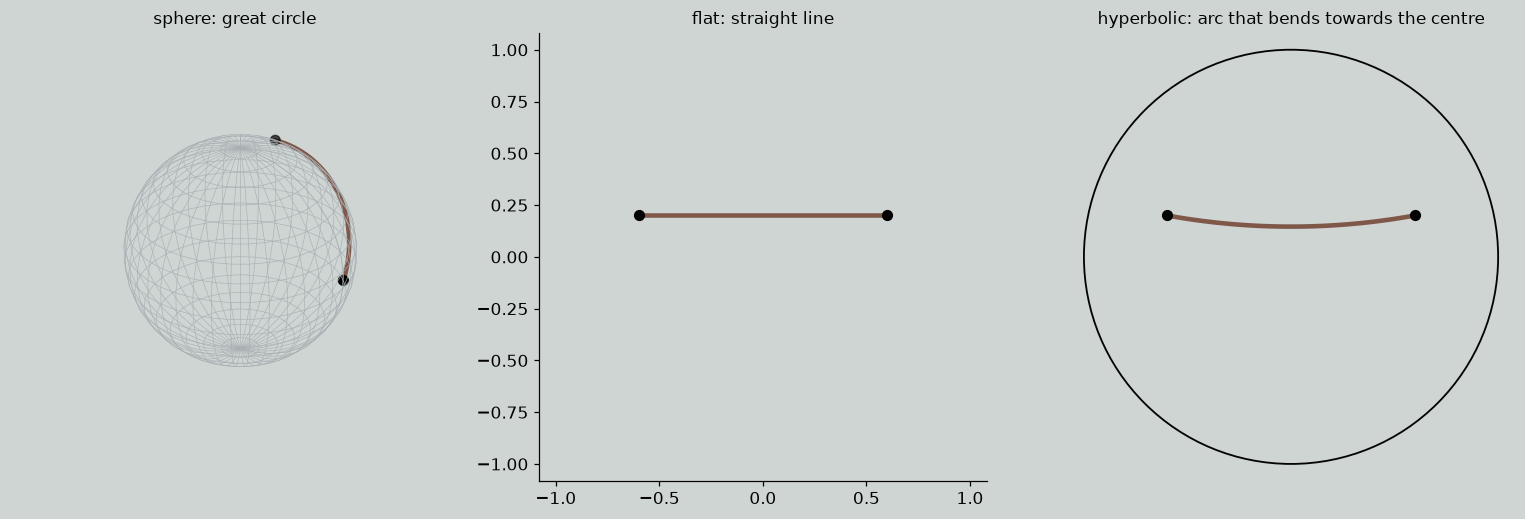

In [12]:
from geomstats.geometry.hypersphere import Hypersphere
from geomstats.geometry.euclidean import Euclidean
from geomstats.geometry.poincare_ball import PoincareBall as GSPoincareBall

sphere2, plane, disk2 = Hypersphere(dim=2), Euclidean(dim=2), GSPoincareBall(dim=2)
t = np.linspace(0, 1, 60)

pairs = {
    "sphere": (sphere2, np.array([1.0, 0.0, 0.0]), np.array([0.0, 0.6, 0.8])),
    "flat": (plane, np.array([-0.6, 0.2]), np.array([0.6, 0.2])),
    "hyperbolic": (disk2, np.array([-0.6, 0.2]), np.array([0.6, 0.2])),
}
paths = {}
for name, (space, a, b) in pairs.items():
    paths[name] = space.metric.geodesic(initial_point=a, end_point=b)(t)
    print(f"{name:<11} distance {space.metric.dist(a, b):.4f}")
print(f"\nPoincaré formula by hand for the hyperbolic pair: {poincare_dist([-0.6, 0.2], [0.6, 0.2]):.4f}")
print(f"angle between the two sphere points:              {np.arccos(np.dot([1, 0, 0], [0, 0.6, 0.8])):.4f}")

fig = plt.figure(figsize=(14, 4.8))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.set_facecolor(BG)
uu, vv = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(np.cos(uu) * np.sin(vv), np.sin(uu) * np.sin(vv), np.cos(vv), color=LIGHT_GREY, lw=0.4)
g = paths["sphere"]; ax.plot(g[:, 0], g[:, 1], g[:, 2], color=BROWN, lw=3)
ax.scatter(*np.array([pairs["sphere"][1], pairs["sphere"][2]]).T, color=TEXT, s=40)
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.set_title("sphere: great circle", fontsize=11)

ax = fig.add_subplot(1, 3, 2)
g = paths["flat"]; ax.plot(g[:, 0], g[:, 1], color=BROWN, lw=3)
ax.scatter(*np.array([pairs["flat"][1], pairs["flat"][2]]).T, color=TEXT, s=40, zorder=3)
ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08); ax.set_aspect("equal"); ax.set_title("flat: straight line", fontsize=11)

ax = fig.add_subplot(1, 3, 3)
draw_disk(ax, "hyperbolic: arc that bends towards the centre")
g = paths["hyperbolic"]; ax.plot(g[:, 0], g[:, 1], color=BROWN, lw=3)
ax.scatter(*np.array([pairs["hyperbolic"][1], pairs["hyperbolic"][2]]).T, color=TEXT, s=40, zorder=3)
plt.tight_layout(); plt.show()

**What you're seeing:** three spaces, three shortest paths. On the sphere it's a great circle of length $\pi/2 \approx 1.5708$ (the two points are at right angles). In the plane it's a straight line of length 1.2. In the Poincaré disk the same two points are 2.8873 apart, and the shortest path bows **towards the centre**, because going through the middle, where distances are cheaper, beats hugging the edge. geomstats agrees with our hand-written formula.

Now the curvature picture from the talk. A circle of radius $r$ is $2\pi \sin r$ long on the unit sphere, $2\pi r$ in flat space and $2\pi \sinh r$ in hyperbolic space. You saw these formulas plotted in notebook 02 (Step 2). This time, instead of trusting them, let's **measure** them: use geomstats to walk out a distance $r$ from a centre point in 400 directions, then add up the geodesic distances between neighbouring points around the loop.

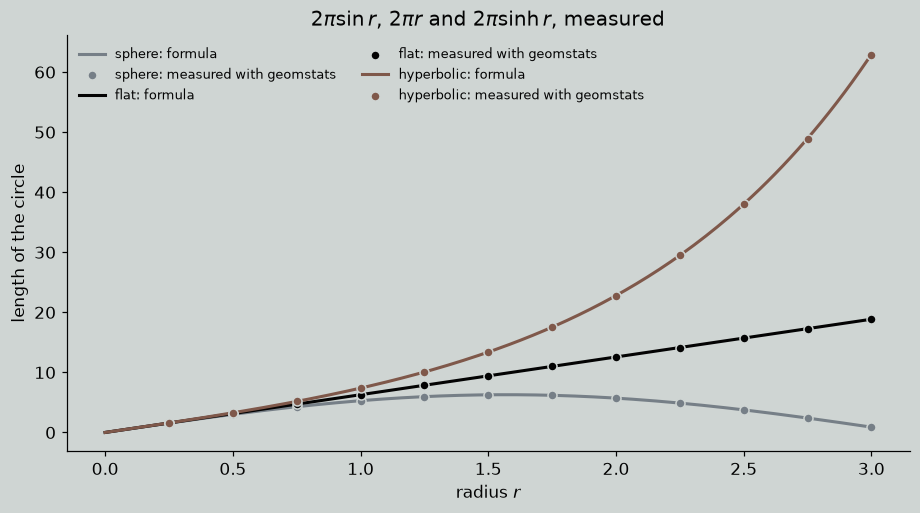

sphere      largest relative difference from the formula: 1.0e-05
flat        largest relative difference from the formula: 1.0e-05
hyperbolic  largest relative difference from the formula: 1.0e-03


In [13]:
def measured_circle(space, centre, directions, radius):
    points = space.metric.exp(radius * directions, base_point=centre)
    nxt = np.roll(points, -1, axis=0)
    return space.metric.dist(points, nxt).sum()

angles = np.linspace(0, 2 * np.pi, 400, endpoint=False)
dirs2 = np.stack([np.cos(angles), np.sin(angles)], axis=1)
north = np.array([0.0, 0.0, 1.0])
dirs_sphere = np.stack([np.cos(angles), np.sin(angles), np.zeros_like(angles)], axis=1)   # tangent at the north pole

def disk_dirs(radius):          # unit-speed directions at the centre of the Poincaré disk (metric factor 2 at 0)
    return dirs2 / 2

radii = np.linspace(0.25, 3.0, 12)
measured = {"sphere": [], "flat": [], "hyperbolic": []}
for rr in radii:
    measured["sphere"].append(measured_circle(sphere2, north, dirs_sphere, rr))
    measured["flat"].append(measured_circle(plane, np.zeros(2), dirs2, rr))
    measured["hyperbolic"].append(measured_circle(disk2, np.zeros(2), disk_dirs(rr), rr))

rs = np.linspace(0, 3.0, 200)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for name, f, col in [("sphere", np.sin, SLATE), ("flat", lambda x: x, TEXT), ("hyperbolic", np.sinh, BROWN)]:
    ax.plot(rs, 2 * np.pi * f(rs), color=col, lw=2, label=f"{name}: formula")
    ax.scatter(radii, measured[name], color=col, s=35, zorder=3, edgecolor=BG, label=f"{name}: measured with geomstats")
ax.set_xlabel("radius $r$"); ax.set_ylabel("length of the circle")
ax.set_title(r"$2\pi\sin r$, $2\pi r$ and $2\pi\sinh r$, measured")
ax.legend(frameon=False, fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

for name, f in [("sphere", np.sin), ("flat", lambda x: x), ("hyperbolic", np.sinh)]:
    err = np.max(np.abs(np.array(measured[name]) - 2 * np.pi * f(radii)) / (2 * np.pi * f(radii)))
    print(f"{name:<11} largest relative difference from the formula: {err:.1e}")

**What you're seeing:** the dots are lengths measured by geomstats, and the curves are the formulas from the slide. They agree to about $10^{-5}$ on the sphere and in the plane, and to about $10^{-3}$ in hyperbolic space. The slightly larger difference is the measuring method. We add up 400 short straight-line (geodesic) segments, and in hyperbolic space a circle bends away from its chords more strongly as it grows, so the chords underestimate it a little more. By radius 3 the hyperbolic circle is already more than three times longer than the flat one.

## Step 8 · What about vector databases?

Here's the uncomfortable part. Vector databases and search libraries (pgvector, Pinecone, FAISS and friends) index cosine similarity, dot product and Euclidean distance. None of them has a built-in hyperbolic index. So what do you do today?

**Option 1: brute force.** For collections up to a few hundred thousand vectors, just compute the hyperbolic distance from the query to everything in one vectorised call. Here are 16-dimensional points in the Poincaré ball.

In [14]:
torch.manual_seed(SEED)
dim = 16
ball64 = geoopt.PoincareBall(c=1.0)

def random_ball_points(count):
    return ball64.expmap0(torch.randn(count, dim, dtype=torch.float32) * 0.6)

query = random_ball_points(1)
for count in [10_000, 100_000]:
    pts = random_ball_points(count)
    ball64.dist(query, pts[:100])                      # warm-up
    t0 = time.perf_counter()
    for _ in range(20):
        d = ball64.dist(query, pts)
        top = torch.topk(-d, k=10).indices
    ms = (time.perf_counter() - t0) / 20 * 1000
    print(f"{count:>7,} points: exact hyperbolic top-10 in {ms:6.2f} ms per query (CPU)")

 10,000 points: exact hyperbolic top-10 in   0.62 ms per query (CPU)
100,000 points: exact hyperbolic top-10 in   2.14 ms per query (CPU)


**What you're seeing:** exact hyperbolic top-10 search over 100,000 points takes a couple of milliseconds per query on a laptop CPU. For a prototype, a demo or a small production collection, brute force is genuinely fine. (Your timings will differ with your hardware.)

**Option 2: re-rank.** Use an ordinary flat index to fetch a shortlist, then re-rank the shortlist by hyperbolic distance. Here the "ordinary index" is plain Euclidean nearest neighbours on the Poincaré coordinates (which is what a vector database would give you), and we check how many of the true hyperbolic top 10 survive for different shortlist sizes.

In [15]:
pts = random_ball_points(100_000)
queries = random_ball_points(200)

def recall_at_10(shortlist):
    hits = 0
    for qv in queries:
        true_top = set(torch.topk(-ball64.dist(qv, pts), k=10).indices.tolist())
        cand = torch.topk(-(pts - qv).norm(dim=1), k=shortlist).indices        # flat index
        reranked = cand[torch.topk(-ball64.dist(qv, pts[cand]), k=10).indices]  # hyperbolic re-rank
        hits += len(true_top & set(reranked.tolist()))
    return hits / (10 * len(queries))

for k in [10, 50, 100, 500]:
    print(f"flat shortlist of {k:>3}, re-ranked hyperbolically: recall@10 = {recall_at_10(k):.3f}")

flat shortlist of  10, re-ranked hyperbolically: recall@10 = 0.071


flat shortlist of  50, re-ranked hyperbolically: recall@10 = 0.160


flat shortlist of 100, re-ranked hyperbolically: recall@10 = 0.237


flat shortlist of 500, re-ranked hyperbolically: recall@10 = 0.490


**What you're seeing:** this is the result I didn't expect. With a shortlist of 100 from the flat index, only about a quarter of the true hyperbolic top 10 survive, and even a shortlist of 500 only gets about half. Euclidean distance on Poincaré coordinates is a poor stand-in for hyperbolic distance, because the same Euclidean distance means very different things near the centre and near the edge. Re-ranking works, but only with big shortlists.

**Option 3: change the coordinates.** Here's a trick I like a lot. On the Lorentz model from Step 2, the hyperbolic distance is

$$d(x, y) = \operatorname{arcosh}\left(x_0 y_0 - x_1 y_1 - \dots - x_n y_n\right),$$

and $\operatorname{arcosh}$ is increasing. So the nearest points to a query $y$ are exactly the points with the **largest** value of $-x_0 y_0 + x_1 y_1 + \dots + x_n y_n$, which is an ordinary dot product between $x$ and the query with its first coordinate flipped, $\tilde{y} = (-y_0, y_1, \dots, y_n)$. Store your points in Lorentz coordinates, use any dot-product (maximum inner product) index, flip one sign in the query, and the ranking you get back is the exact hyperbolic ranking.

In [16]:
def poincare_to_lorentz_batch(x):
    n2 = (x.double() ** 2).sum(-1, keepdim=True)
    return torch.cat([(1 + n2) / (1 - n2), 2 * x.double() / (1 - n2)], dim=-1)

pts_L = poincare_to_lorentz_batch(pts)          # what you'd store in a dot-product index
hits = 0
for qv in queries:
    true_top = set(torch.topk(-ball64.dist(qv.double(), pts.double()), k=10).indices.tolist())
    qL = poincare_to_lorentz_batch(qv[None])[0]
    q_flipped = torch.cat([-qL[:1], qL[1:]])
    dot_top = set(torch.topk(pts_L @ q_flipped, k=10).indices.tolist())   # plain dot-product search
    hits += len(true_top & dot_top)
print(f"dot-product search on Lorentz coordinates: recall@10 = {hits / (10 * len(queries)):.3f}")

dot-product search on Lorentz coordinates: recall@10 = 1.000


**What you're seeing:** a recall of 1.000. Plain dot-product search over Lorentz coordinates, with one sign flipped in the query, gives exactly the hyperbolic top 10 for every one of the 200 queries. You don't need a new kind of index for exact search, just a change of coordinates.

Let's be honest about where this stands. Brute force is fine for prototypes and for collections that fit comfortably in memory. Re-ranking a flat shortlist is easy to bolt on, but as you just saw it needs a big shortlist to be any good. The Lorentz trick is exact, but the approximate dot-product indexes inside vector databases (HNSW and friends) are tuned on ordinary embeddings, Lorentz coordinates get very large near the edge, and I haven't seen anyone benchmark how well the two get along at scale. Proper hyperbolic indexing is engineering work that has only just started (van Spengler & Mettes, ICML 2025, for example, look at tree embeddings in hyperbolic space that are both low-distortion and GPU-friendly). If you want a meaty open-source project, this is one.

## Step 9 · Takeaway

The maths is packaged: geoopt for curved spaces and optimisers, gensim for a five-line start, HypLL for hyperbolic layers and geomstats for geometry on almost any manifold. The costs are real (silent precision limits, optimisers that have to follow the curve, no hyperbolic index in your vector database) but they're manageable for experiments. A good weekend project is to take your own taxonomy or chart of accounts, embed it both ways, and compare.